# E-commerce Product Analytics — Acquisition and Monetization (CAC/LTV)

## 1. Business Questions

This analysis compares acquisition channels by cost and revenue and answers the following questions:

- How much does it cost to acquire a user and a paying subscriber in each channel (CAC)?
- How much subscription revenue does a user bring, and which plans bring it?
- How does the revenue of a channel's users compare with its acquisition cost (LTV/CAC)?
- Does the comparison of channels hold when a few large customers are excluded and when all users are observed for the same period?

## 2. Metrics and Definitions

- **CAC (customer acquisition cost)** — acquisition cost divided by the number of acquired customers. Here it is calculated in two ways: **per acquired user** (total channel cost / acquired users) and **per paying subscriber** (total channel cost / users with a paid plan, any plan except Free). The second is a blended metric: the cost of all acquired users is divided by the paying ones, because the data do not show a separate cost of acquiring paying users.
- **Revenue of a subscription** — billed months × `mrr_amount` (monthly recurring revenue). Every started 30-day period is billed, with at least one month.
- **LTV to date** — subscription revenue up to the snapshot date per acquired user. Users without a subscription or with the Free plan count as 0, so LTV and CAC use the same denominator — all acquired users of the channel.
- **12-month LTV** — subscription revenue in the first 12 months (360 days) after signup per acquired user, only for users whose 12 months are fully observed.
- **LTV/CAC** — LTV divided by CAC per acquired user, i.e. channel revenue / channel cost. A ratio above 1 means that the observed revenue of the channel's users exceeds the cost of acquiring them. It does not prove that the channel is profitable: the cost of serving customers, other operating costs and the full customer lifetime are not taken into account.

LTV here is gross subscription revenue observed in the data, not a forecast of future revenue and not margin. Definitions follow Amplitude's guides to CAC and LTV (see References).

## 3. Data

The analysis uses three tables:

- `acquisition_costs` — one row per user (1,000 users): `acquisition_channel` and `cost`, the acquisition cost attributed to the user
- `subscriptions` — one subscription per subscriber (675 users): `plan`, `start_date`, `end_date` (empty for active subscriptions) and `mrr_amount`
- `users` — `signup_time`, used for the 12-month horizon

Events are not used: purchase events in `events` have no amount. The `conversions` table is not used either: it does not agree with `subscriptions` (see the data checks below).

**Snapshot date.** The `users`, `subscriptions` and `conversions` tables end on 20 May 2025, although events go on to August 2025. The snapshot date is the last date in `subscriptions` (the latest `start_date`, 20 May 2025); active subscriptions are counted up to this date. The latest start date is used as a proxy for the end of the subscription data; in other data, it is not necessarily the date up to which the data are complete.

The CAC and LTV logic comes from an earlier version of this analysis. Section 5 shows how the snapshot date and the billing rule of the LTV draft affect revenue. Query results are stored in `data/results/06_cac_ltv/` and re-created with `python scripts/export_results.py`.

### Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.titleweight': 'bold',
    'axes.grid': True,
    'grid.alpha': 0.3
})

RESULTS = "../data/results/06_cac_ltv/"

### Data checks

[00_data_checks.sql](../sql/06_cac_ltv/00_data_checks.sql)

**Check 1. Do conversions agree with subscriptions?** If they did, `paid_plan_purchase` would come after `trial_signup`, close to the subscription start, and only for users with a paid plan.

In [2]:
pd.read_csv(RESULTS + "conversions_consistency_check.csv")

,users_with_paid_plan_purchase,paid_before_trial,median_days_paid_before_trial,paid_users_with_subscription,paid_within_1_day_of_subscription_start,free_plan_users_with_paid_plan_purchase,enterprise_subscribers,enterprise_with_paid_plan_purchase
0,398,183,102.0,265,3,74,41,19


Of 398 users with a `paid_plan_purchase`, 183 paid before their `trial_signup` (a median of 102 days earlier), and 133 have no subscription at all. Among the 265 with a subscription, the payment falls within one day of the subscription start in only 3 cases. 74 users with the Free plan have a `paid_plan_purchase`, while only 19 of 41 Enterprise subscribers do. The `conversions` table therefore does not describe the same events as `subscriptions`, so revenue and paying users are taken from `subscriptions` only.

**Check 2. Which period do subscription end dates cover?** If end dates were recorded for the whole period, subscriptions that started in 2023 could also end within their first 90 days.

In [3]:
display(pd.read_csv(RESULTS + "subscription_end_date_range.csv"))
display(pd.read_csv(RESULTS + "subscription_ended_90_days_by_quarter.csv"))

,subscriptions,ended_subscriptions,first_start_date,first_end_date,last_end_date
0,675,201,2023-01-28 00:00:00.000,2024-05-03 00:00:00.000,2025-04-28 00:00:00.000


,start_quarter,subscriptions,observed_90_days,ended_within_90_days,ended_within_90_days_pct
0,2023-01-01 00:00:00.000,6,6,0,0.0
1,2023-04-01 00:00:00.000,12,12,0,0.0
2,2023-07-01 00:00:00.000,20,20,0,0.0
3,2023-10-01 00:00:00.000,32,32,0,0.0
4,2024-01-01 00:00:00.000,55,55,1,1.8
5,2024-04-01 00:00:00.000,57,57,10,17.5
6,2024-07-01 00:00:00.000,63,63,11,17.5
7,2024-10-01 00:00:00.000,122,122,23,18.9
8,2025-01-01 00:00:00.000,154,85,11,12.9
9,2025-04-01 00:00:00.000,154,0,0,NaN


End dates cover only 3 May 2024 – 28 April 2025, although subscriptions start from 28 January 2023. None of the 70 subscriptions that started in 2023 ended within their first 90 days, and only 1 of 55 that started in the first quarter of 2024 (whose first 90 days mostly fall before May 2024), compared with 17.5–18.9% of those that started from April to December 2024.

This suggests that end dates before May 2024 are not recorded. If so, some subscriptions that actually ended earlier are counted as active until at least May 2024, and the revenue of subscribers from 2023 and early 2024 — and the LTV of users acquired then — may be overstated. The data cannot show how large this effect is. It matters most for the 12-month LTV (Section 7): users with a fully observed 12-month horizon signed up before the end of May 2024, so much of their horizon falls in the period without recorded end dates.

## 4. CAC by Channel

### Business Question

How much does it cost to acquire a user and a paying subscriber in each channel?

### SQL

[01_cac.sql](../sql/06_cac_ltv/01_cac.sql)

```sql
SELECT
    acquisition_channel,
    COUNT(*) AS users,
    ROUND(SUM(cost), 2) AS total_cost,
    ROUND(SUM(cost) / COUNT(*), 2) AS cac_per_user,
    CAST(SUM(paying) AS INTEGER) AS paying_subscribers,
    ROUND(SUM(cost) / SUM(paying), 2) AS cac_per_paying_subscriber
FROM user_costs
GROUP BY acquisition_channel
```

### Results

In [4]:
cac = pd.read_csv(RESULTS + "cac_by_channel.csv")

cac

,acquisition_channel,users,total_cost,cac_per_user,min_cost,max_cost,paying_subscribers,cac_per_paying_subscriber
0,Direct,119,296.15,2.49,0.07,4.97,52,5.70
1,Email Campaign,104,906.74,8.72,2.07,14.85,45,20.15
2,Organic Search,99,1257.18,12.70,5.30,19.85,44,28.57
3,Content Marketing,109,1850.15,16.97,8.11,24.82,56,33.04
4,Referral,110,2793.57,25.40,10.55,38.88,48,58.20
5,Social Media,93,3418.28,36.76,15.03,57.30,43,79.49
6,Paid Search,119,6140.00,51.60,20.17,79.39,52,118.08
7,App Store,132,8537.19,64.68,25.33,99.72,70,121.96
8,Partner,115,8015.09,69.70,30.09,119.24,51,157.16


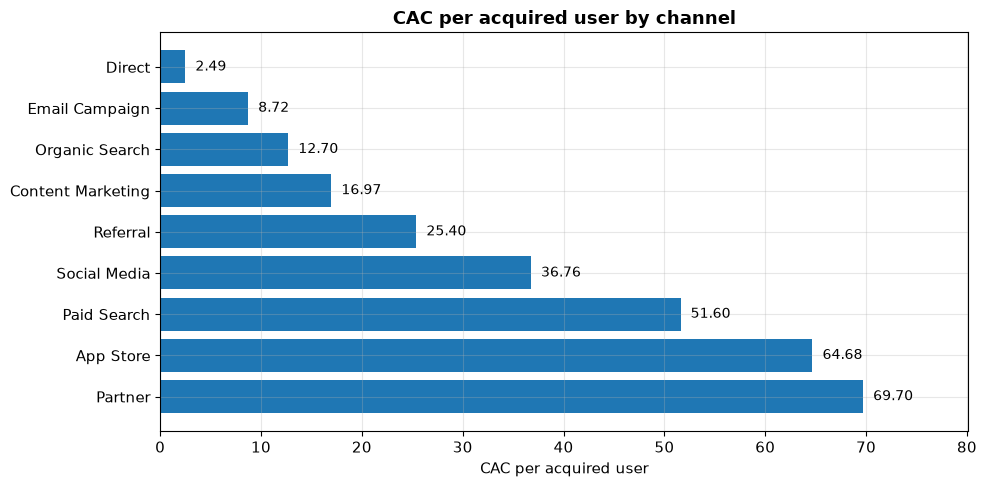

In [5]:
plt.figure(figsize=(10, 5))
bars = plt.barh(cac["acquisition_channel"], cac["cac_per_user"], color="tab:blue")
plt.gca().invert_yaxis()

for bar, value in zip(bars, cac["cac_per_user"]):
    plt.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"{value:.2f}", va="center", fontsize=10)

plt.title("CAC per acquired user by channel")
plt.xlabel("CAC per acquired user")
plt.xlim(0, cac["cac_per_user"].max() * 1.15)
plt.tight_layout()
plt.show()

### Finding

CAC per acquired user ranges from 2.49 (Direct) to 69.70 (Partner). The cost ranges of the channels barely overlap: for example, the cost of a Direct user is 0.07–4.97, and of a Partner user 30.09–119.24. Such clear separation looks like a property of the synthetic data rather than of real campaigns.

461 of 1,000 users (46.1%) have a paid plan. CAC per paying subscriber is about twice CAC per user in every channel: from 5.70 (Direct) to 157.16 (Partner).

## 5. Subscription Revenue

### Business Question

How much subscription revenue is there, and which plans bring it?

### SQL

[02_revenue.sql](../sql/06_cac_ltv/02_revenue.sql)

Billed months of a subscription:

```sql
GREATEST(CEIL((LEAST(COALESCE(end_date, snapshot_date), snapshot_date) - start_date) / 30.0), 1) AS months
```

### Snapshot date check

The LTV draft (an earlier version of this analysis, reproduced in `02_revenue.sql`) differs from this notebook in two ways: it used 28 April 2025, the last `end_date`, as the snapshot date, and it had no minimum billed period. The table applies the two changes one at a time.

In [6]:
pd.read_csv(RESULTS + "revenue_snapshot_check.csv")

,step,method,subscriptions_without_billed_months,total_revenue
0,1,"Draft: snapshot 2025-04-28, no minimum",84,149935.68
1,2,"Snapshot 2025-05-20, no minimum",7,166588.84
2,3,"Snapshot 2025-05-20, at least one month (this ...",0,167112.37


With the draft method, 84 subscriptions get no billed months, and total revenue is 149,935.68 instead of 167,112.37 (10.3% lower). Almost all of the difference of 17,176.69 comes from the snapshot date: moving it to 20 May 2025 adds 16,653.16 (97%). Applying a minimum of one billed month adds 523.53 in revenue (3%) and eliminates the remaining seven subscriptions with zero billed months; all seven start on 20 May 2025, the snapshot date, and have no end date. The rest of the notebook uses method 3.

### Revenue by plan

In [7]:
revenue_by_plan = pd.read_csv(RESULTS + "revenue_by_plan.csv")

revenue_by_plan

,plan,subscribers,active_subscriptions,avg_mrr,avg_billed_months,revenue,pct_of_revenue
0,Enterprise,41,31,362.03,5.3,83401.60,49.9
1,Pro,88,59,73.80,6.3,40773.06,24.4
2,Premium,129,91,34.13,5.4,23594.52,14.1
3,Basic,203,140,14.94,6.5,19343.19,11.6
4,Free,214,153,0.00,6.6,0.00,0.0


### Finding

Enterprise brings half of all subscription revenue: 41 subscribers (4.1% of users, 6.1% of subscribers) with an average MRR of 362.03 bring 49.9% of revenue. Pro brings 24.4%, Premium 14.1% and Basic 11.6%; the 214 Free subscribers bring no revenue.

Subscriptions are short in the observed period: on average 5.3–6.6 billed months per plan, and 474 of 675 subscriptions are still active on the snapshot date. So the observed revenue is revenue to date, not the full lifetime revenue of these subscribers.

## 6. LTV to Date and LTV/CAC by Channel

### Business Question

How does the revenue of a channel's users compare with its acquisition cost, and does the comparison hold without the few Enterprise subscribers?

### SQL

[03_ltv_cac.sql](../sql/06_cac_ltv/03_ltv_cac.sql)

LTV to date and LTV/CAC per channel; for the comparison without Enterprise, Enterprise subscribers are removed from both revenue and cost:

```sql
SELECT
    acquisition_channel,
    ROUND(SUM(cost) / COUNT(*), 2) AS cac_per_user,
    ROUND(SUM(revenue) / COUNT(*), 2) AS ltv_to_date,
    ROUND(SUM(revenue) / SUM(cost), 2) AS ltv_cac,
    ROUND(SUM(revenue) FILTER (WHERE enterprise = 0)
          / SUM(cost) FILTER (WHERE enterprise = 0), 2) AS ltv_cac_without_enterprise
FROM user_value
GROUP BY acquisition_channel
```

The draft averaged LTV over subscribers only and CAC over all acquired users; here both use all acquired users.

### Results

In [8]:
ltv_cac = pd.read_csv(RESULTS + "ltv_cac_by_channel.csv")
ltv_cac["rank"] = ltv_cac["ltv_cac"].rank(ascending=False).astype(int)
ltv_cac["rank_without_enterprise"] = ltv_cac["ltv_cac_without_enterprise"].rank(ascending=False).astype(int)

ltv_cac

,acquisition_channel,users,cac_per_user,ltv_to_date,median_revenue,ltv_cac,enterprise_users,enterprise_pct_of_revenue,ltv_to_date_without_enterprise,ltv_cac_without_enterprise,rank,rank_without_enterprise
0,Direct,119,2.49,131.65,0.00,52.90,5,33.0,92.05,37.16,1,1
1,Content Marketing,109,16.97,247.86,15.23,14.60,8,69.9,80.44,4.72,2,4
2,Email Campaign,104,8.72,111.14,0.00,12.75,3,28.3,82.01,9.46,3,2
3,Organic Search,99,12.70,156.26,0.00,12.31,4,49.5,82.19,6.54,4,3
4,Referral,110,25.40,137.46,0.00,5.41,4,43.2,80.98,3.22,5,5
5,Social Media,93,36.76,185.31,0.00,5.04,4,52.5,91.93,2.52,6,6
6,App Store,132,64.68,234.40,16.36,3.62,7,64.7,87.30,1.35,7,9
7,Paid Search,119,51.60,147.88,0.00,2.87,4,44.3,85.16,1.66,8,7
8,Partner,115,69.70,143.57,0.00,2.06,2,30.2,102.01,1.46,9,8


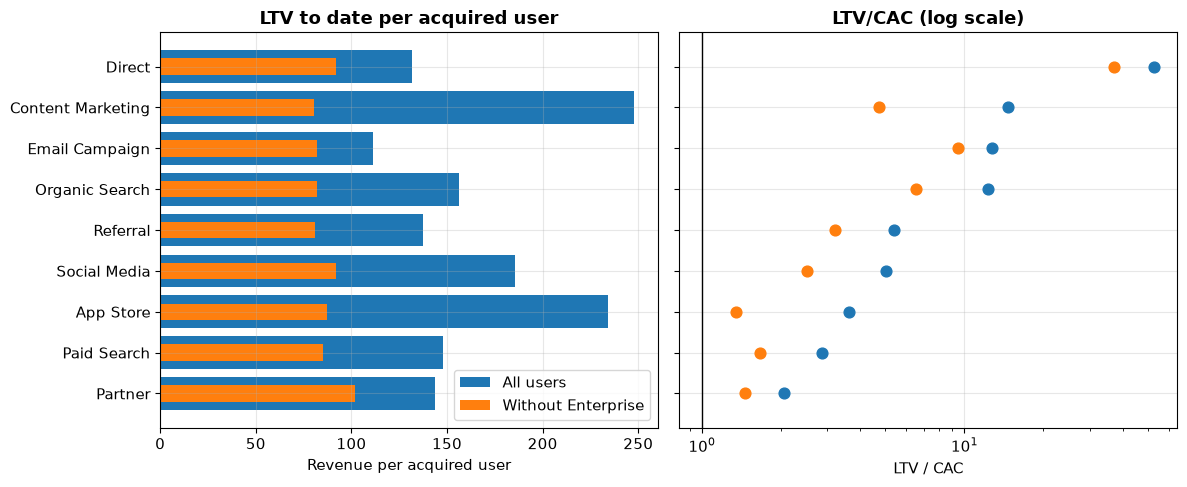

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
data = ltv_cac.sort_values("ltv_cac")

axes[0].barh(data["acquisition_channel"], data["ltv_to_date"], color="tab:blue", label="All users")
axes[0].barh(data["acquisition_channel"], data["ltv_to_date_without_enterprise"], color="tab:orange", height=0.4,
             label="Without Enterprise")
axes[0].set_title("LTV to date per acquired user")
axes[0].set_xlabel("Revenue per acquired user")
axes[0].legend(loc="lower right")

axes[1].scatter(data["ltv_cac"], data["acquisition_channel"], color="tab:blue", s=60, zorder=3, label="All users")
axes[1].scatter(data["ltv_cac_without_enterprise"], data["acquisition_channel"], color="tab:orange", s=60, zorder=3,
                label="Without Enterprise")
axes[1].set_xscale("log")
axes[1].axvline(1, color="black", linewidth=1)
axes[1].set_title("LTV/CAC (log scale)")
axes[1].set_xlabel("LTV / CAC")

plt.tight_layout()
plt.show()

### Finding

LTV to date ranges from 111.14 (Email Campaign) to 247.86 (Content Marketing) per acquired user, and LTV/CAC from 2.06 (Partner) to 52.90 (Direct). All channels have LTV/CAC above 1. Most users bring no revenue: the median revenue per user is 0 in 7 of 9 channels.

The comparison of LTV depends on a few Enterprise subscribers. Each channel has 2 to 8 of them, and they bring 28.3–69.9% of the channel's revenue. Without Enterprise, LTV to date is similar in all channels: 80.44–102.01 per user. Content Marketing, the channel with the highest LTV, falls from 2nd to 4th place by LTV/CAC (14.60 → 4.72): 69.9% of its revenue comes from 8 Enterprise subscribers.

So, without Enterprise, the differences in LTV/CAC come mainly from CAC: Direct stays first (37.16), because its CAC is 2.49, and the channels with the highest CAC (Paid Search, Partner, App Store) have the lowest ratios (1.35–1.66). With only 2–8 Enterprise subscribers per channel, the differences in LTV with Enterprise depend on a few customers and are not interpreted as differences in channel quality.

## 7. 12-Month LTV and LTV/CAC

### Business Question

Does the comparison of channels hold when all users are observed for the same period after signup?

### SQL

[04_ltv_12_months.sql](../sql/06_cac_ltv/04_ltv_12_months.sql)

LTV to date depends on how long users have been observed: users who signed up recently have had little time to pay. Here revenue is counted only in the first 12 months (360 days) after signup. A user is included only if the whole horizon is observed: signup date + 360 days must be before the snapshot date (20 May 2025). Subscriptions that start after the horizon end bring no revenue in it. This is the same conservative rule as in the previous notebooks.

```sql
CASE
    WHEN s.start_date < h.horizon_end
    THEN GREATEST(CEIL((LEAST(COALESCE(s.end_date, snapshot_date),
                              snapshot_date,
                              h.horizon_end)
                        - s.start_date) / 30.0), 1) * s.mrr_amount
    ELSE 0
END AS revenue_12m
```

### Results

In [10]:
ltv_12m = pd.read_csv(RESULTS + "ltv_12_months_by_channel.csv")

ltv_12m

,acquisition_channel,users,eligible_users,pct_eligible,cac_per_user,ltv_12_months,ltv_cac_12_months,enterprise_users,ltv_cac_12_months_without_enterprise
0,Direct,119,67,56.3,2.51,88.13,35.18,1,29.54
1,Content Marketing,109,64,58.7,16.20,161.75,9.98,3,3.79
2,Email Campaign,104,63,60.6,8.96,45.91,5.12,0,5.12
3,Organic Search,99,59,59.6,12.57,61.00,4.85,0,4.85
4,Referral,110,63,57.3,25.19,60.93,2.42,1,1.68
5,Paid Search,119,66,55.5,51.53,119.25,2.31,1,1.17
6,App Store,132,67,50.8,62.78,140.38,2.24,1,0.85
7,Social Media,93,58,62.4,38.18,83.28,2.18,1,1.82
8,Partner,115,62,53.9,67.06,60.99,0.91,0,0.91


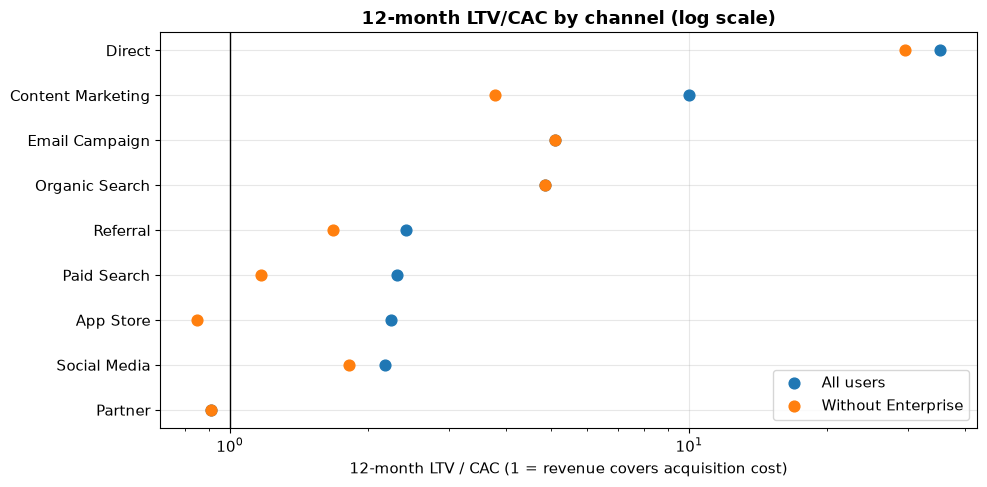

In [11]:
data = ltv_12m.sort_values("ltv_cac_12_months")

plt.figure(figsize=(10, 5))
plt.scatter(data["ltv_cac_12_months"], data["acquisition_channel"], color="tab:blue", s=60, zorder=3, label="All users")
plt.scatter(data["ltv_cac_12_months_without_enterprise"], data["acquisition_channel"], color="tab:orange", s=60, zorder=3,
            label="Without Enterprise")
plt.xscale("log")
plt.axvline(1, color="black", linewidth=1)

plt.title("12-month LTV/CAC by channel (log scale)")
plt.xlabel("12-month LTV / CAC (1 = revenue covers acquisition cost)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Finding

569 of 1,000 users have a fully observed 12-month horizon, 50.8–62.4% of users in each channel, so the share of observed users is similar across channels. These users signed up before the end of May 2024, so much of their horizon falls in the period without recorded subscription end dates (see the data checks in Section 3), and their 12-month revenue may be overstated.

Within 12 months after signup, LTV ranges from 45.91 (Email Campaign) to 161.75 (Content Marketing) per user, and LTV/CAC from 0.91 (Partner) to 35.18 (Direct). Partner is the only channel where the revenue of its users in the first 12 months does not yet cover the acquisition cost. This does not necessarily mean that the channel is unprofitable over the full customer lifetime: it only shows that the cost is not paid back on this horizon. Without Enterprise, App Store is also below 1 (0.85).

Direct's result is the most stable: its 12-month LTV/CAC is 35.18, and 29.54 without Enterprise. The eligible users include only 8 Enterprise subscribers (0–3 per channel), so Content Marketing's high 12-month LTV again depends on 3 customers: without them, its ratio falls from 9.98 to 3.79. This ratio is still above 1, so the channel's result depends strongly on a few large customers, but it is not unprofitable on this measure. As in Section 6, the cheapest channels (Direct, Email Campaign, Organic Search) are among the top four, and Partner is last.

## 8. Key Findings

- **CAC differs strongly between channels.** CAC per acquired user ranges from 2.49 (Direct) to 69.70 (Partner), and per paying subscriber from 5.70 to 157.16; the cost ranges of the channels barely overlap.
- **Half of revenue comes from Enterprise.** 41 Enterprise subscribers (4.1% of users) bring 49.9% of subscription revenue; most users bring no revenue.
- **The draft method understates revenue.** With the draft method, 84 subscriptions get no billed months, and revenue is 10.3% lower; 97% of the difference comes from the snapshot date (28 April instead of 20 May 2025).
- **Without Enterprise, revenue per user is similar across channels.** LTV to date is 80.44–102.01 per user without Enterprise, so differences in LTV/CAC come mainly from CAC: Direct is first (52.90; 37.16 without Enterprise), Partner, App Store and Paid Search are last.
- **Direct's result does not depend on large customers; Content Marketing's does.** Direct's 12-month LTV/CAC is 35.18, and 29.54 without Enterprise; Content Marketing's falls from 9.98 to 3.79 without its 3 Enterprise subscribers. Whether cheap channels like Direct keep their low CAC at a larger budget is not shown by the data.
- **Partner does not pay back within 12 months.** 12-month LTV/CAC is 0.91 for Partner and above 1 for all other channels; without Enterprise, App Store is also below 1 (0.85). This is payback on a 12-month horizon, not profitability over the customer lifetime.

## 9. Product Interpretation

In a real product, these results would suggest the following questions for the marketing budget:

1. **Cheap channels look most efficient, but their scale is unknown.** Direct, Email Campaign and Organic Search have the highest LTV/CAC because their CAC is low. The data do not show whether more users can be acquired through them at the same cost.
2. **Expensive channels need a longer payback period.** Partner does not pay back within 12 months; App Store pays back within 12 months only thanks to one Enterprise customer (2.24, without Enterprise 0.85), and Paid Search's ratio halves without its one Enterprise customer (2.31 → 1.17). Before cutting these channels, it is worth checking whether their users stay subscribed long enough to pay back later.
3. **Large customers should be analyzed separately.** When a few Enterprise customers bring half of revenue, LTV by channel mostly shows where these customers came from. A separate analysis of how Enterprise customers are acquired would be more useful than an average LTV.

These are associations in observed data, not effects of the channels: a channel comparison does not show what would happen if the budget were moved.

## 10. Next Questions

1. How long do subscriptions last by plan and channel, and how would a churn-based LTV forecast change the comparison?
2. Through which channels and after which actions do users upgrade to Enterprise?
3. How long does it take for a paying subscriber to pay back their CAC (payback period) in each channel?
4. Do channels differ in engagement and retention (`01_engagement.ipynb`, `02_retention_cohorts.ipynb`)?

## 11. Limitations

- The dataset is synthetic: cost ranges of the channels barely overlap, which looks generated rather than observed.
- LTV is gross subscription revenue observed up to the snapshot date (or in 12 months), not a forecast of lifetime revenue and not margin; 474 of 675 subscriptions are still active.
- LTV/CAC compares gross revenue with acquisition cost; costs of serving customers and other operating costs are not in the data, so a ratio above 1 does not prove profitability.
- CAC per paying subscriber is a blended metric (all acquisition cost / paying subscribers).
- The snapshot date is the latest subscription start date, used as a proxy for the end of the subscription data.
- Subscription end dates are recorded only from May 2024 to April 2025; if earlier ends are missing, revenue and LTV of users acquired in 2023 and early 2024 — and the 12-month LTV in particular — may be overstated.
- The `conversions` table does not agree with `subscriptions` (payments before trials, payments without subscriptions, paid purchases on the Free plan), so it is not used.
- Billing is approximated: every started 30-day period of a subscription is billed at `mrr_amount`, with at least one month; actual payments are not in the data.
- The `subscriptions` table has one subscription per user, so upgrades, downgrades and repeat subscriptions are not visible.
- A few Enterprise subscribers (2–8 per channel, 0–3 in the 12-month horizon) strongly affect LTV by channel.
- The analysis is observational and does not establish causality.

## 12. References

CAC and LTV definitions follow Amplitude's product analytics materials:

- Amplitude — [The Complete Guide To Customer Acquisition Cost (CAC)](https://amplitude.com/explore/metrics/guide-to-customer-acquisition-cost)
- Amplitude — [What is LTV? Why LTV Matters to Business](https://amplitude.com/explore/metrics/ltv-in-business-guide)
- Dataset — [adisomani/duckdb_product_analytics_tutorial](https://github.com/adisomani/duckdb_product_analytics_tutorial)